In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
import pandas as pd
import openflash
import gmsh, pygmsh
print(type(openflash))
print(openflash.__path__)
print(openflash.__file__)


# --- Import core modules from package ---
try:
    from openflash import *
    from openflash.multi_constants import g
    print("OpenFLASH modules imported successfully!")
except ImportError as e:
    print(f"Error importing OpenFLASH modules. Error: {e}")

# Set NumPy print options for better readability
np.set_printoptions(threshold=np.inf, linewidth=np.inf, precision=8, suppress=True)
from openflash.multi_constants import rho #need for BEM

import time
import capytaine as cpt
from capytaine.io.meshio import load_from_meshio
import sys
import os
import xarray as xr
# Define the path to the directory containing the package
utils_path = r"C:\Users\15183\OpenFLASH\sea-lab-utils"

if utils_path not in sys.path:
    sys.path.append(utils_path)



<class 'module'>
['c:\\Users\\15183\\miniconda3\\envs\\openflash-env\\Lib\\site-packages\\openflash']
c:\Users\15183\miniconda3\envs\openflash-env\Lib\site-packages\openflash\__init__.py
OpenFLASH modules imported successfully!


In [8]:
a_list = [[1.5], [3.5, 5.5]] 
d_list = [[5], [3, 1]]
betas = np.array([0.0])
heaving = [True, True]
omegas = np.linspace(0.1, 2.5, 25)

h = 100
rho = 1025
g = 9.81
mesh_size_factor = 0.8

mesh_list = []
lid_mesh_list = []
fb_list = []
v_shift = 1e-4

for i, heave in enumerate(heaving):
    a_vals = a_list[i]
    d_vals = d_list[i]

    with pygmsh.occ.Geometry() as geom:
        gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)

        if len(a_vals) == 1:
            cyls = geom.add_cylinder([0, 0, v_shift], [0, 0, -d_vals[0]], a_vals[0])
        else:
            print("multi cyl")
            cyls = None
            for a, d in zip(a_vals, d_vals):
                cyl = geom.add_cylinder([0, 0, v_shift], [0, 0, -d], a)
                if cyls is None:
                    cyls = cyl
                else:
                    # Pass entities as a list [cyls, cyl]
                    cyls = geom.boolean_union([cyls, cyl], delete_first=True, delete_other=True)

        # Determine cut-out for previous body
        if i > 0:
            print("hollow")
            # Slightly extend z-bounds (+1e-3, -2e-3) to avoid coincident boundary surface failures
            max_d = max(d_vals)
            r_cut = a_list[i-1][-1]
            hollow = geom.add_cylinder([0, 0, v_shift + 1e-3], [0, 0, -(max_d + 2e-3)], r_cut)
            
            # Pass input and tool as a list [cyls, hollow]
            cyls = geom.boolean_difference(cyls, hollow, delete_first=True, delete_other=True)

        mesh = geom.generate_mesh()

    # Convert Mesh & Instantiate FloatingBody
    mesh_name = f"mesh{i}"
    mesh_obj = load_from_meshio(mesh, mesh_name)
    lid_mesh_obj = mesh_obj.generate_lid(z=-1e-2)
    mesh_list.append(mesh_obj)
    lid_mesh_list.append(lid_mesh_obj)

    fb_name = f"fb{i}"
    fb = cpt.FloatingBody(mesh=mesh_obj, lid_mesh=lid_mesh_obj, name=fb_name).keep_immersed_part()
    if heave:
        fb.add_translation_dof(name='Heave')
    fb_list.append(fb)

multi cyl
hollow


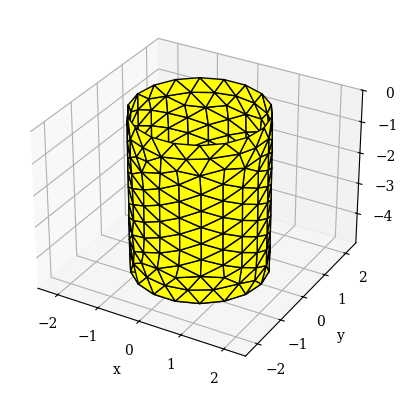

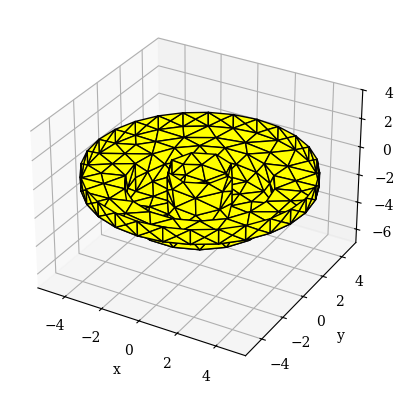

In [9]:
for fb in fb_list:
    fb.show_matplotlib()

In [10]:
combinedfb = cpt.FloatingBody.join_bodies(*fb_list)
combined_dofs_keys = list(combinedfb.dofs.keys())
print(f"DOFs: {combined_dofs_keys}")
input_dict = {"omega":omegas,
            "wave_direction":betas,
            "radiating_dof":combined_dofs_keys,
            "water_depth":h,
            "rho":rho,
            "g":g}
test_matrix = xr.Dataset(coords=input_dict)
cpt_data = cpt.BEMSolver().fill_dataset(test_matrix, combinedfb)

Output()

DOFs: ['fb0__Heave', 'fb1__Heave']


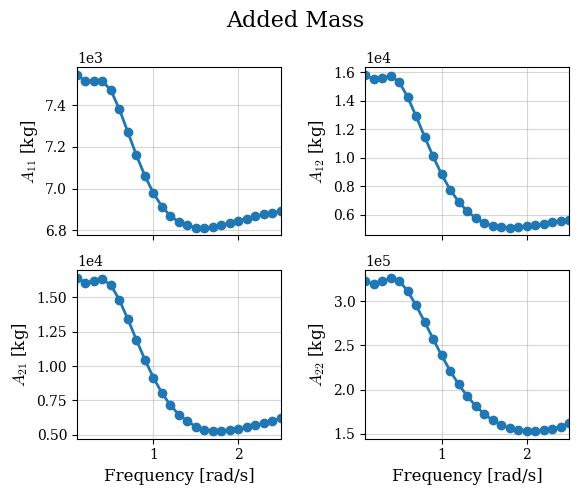

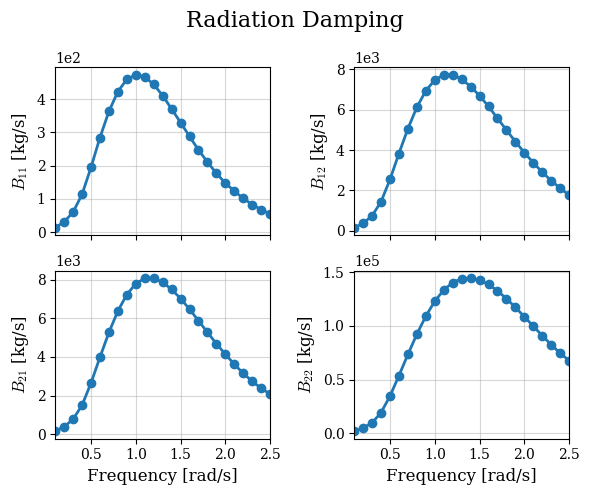

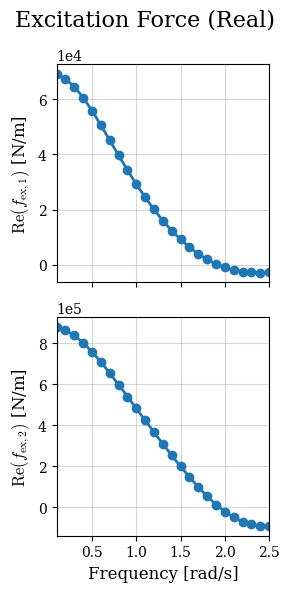

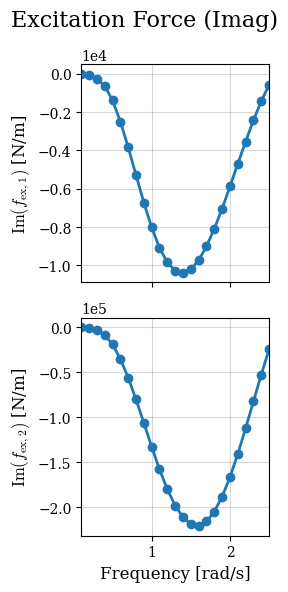

In [11]:
N_dofs = len(combined_dofs_keys)
N_omega = len(omegas)
N_beta = len(betas)

font_size = 12

# Added Mass and Radiation Damping
rad_data_list = {"Added Mass":cpt_data.added_mass,
                 "Radiation Damping":cpt_data.radiation_damping}
for data_name, rad_data in rad_data_list.items():
    fig, ax = plt.subplots(N_dofs,N_dofs, figsize=(3*N_dofs,2.5*N_dofs), sharex=True)
    for i_inf, inf_dof in enumerate(combined_dofs_keys):
        for i_rad, rad_dof in enumerate(combined_dofs_keys):
            ax[i_inf,i_rad].plot(omegas,
                                 rad_data.sel(influenced_dof=inf_dof,
                                              radiating_dof=rad_dof).values.flatten(),
                                               marker='o',
                                                markersize=6,
                                                 linewidth=2)
            ax[i_inf, i_rad].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
            
            if i_inf==N_dofs-1:
                ax[i_inf,i_rad].set_xlabel('Frequency [rad/s]', fontsize=font_size)
            if data_name=="Added Mass":
                ylab = f"$A_{{{i_inf+1}{i_rad+1}}}$ [kg]"
            elif data_name=="Radiation Damping":
                ylab = f"$B_{{{i_inf+1}{i_rad+1}}}$ [kg/s]"
            ax[i_inf,i_rad].set_ylabel(ylab, fontsize=font_size)
            ax[i_inf,i_rad].set_xlim([np.min(omegas), np.max(omegas)])
            ax[i_inf,i_rad].grid(True, alpha=0.5)
            ax[i_inf,i_rad].set_axisbelow(True)
        fig.suptitle(data_name, fontsize=font_size + 4)
    plt.tight_layout()

# Excitation force
ex_data_list = {"Excitation Force (Real)":np.real(cpt_data.excitation_force),
                "Excitation Force (Imag)":np.imag(cpt_data.excitation_force)}
for data_name, ex_data in ex_data_list.items():
    fig, ax = plt.subplots(N_dofs,N_beta, figsize=(3*N_beta,3*N_dofs), sharex=True)
    if N_beta==1:
        ax=ax[:,None]
    for i_inf, inf_dof in enumerate(combined_dofs_keys):
        for i_beta, beta in enumerate(betas):
            ax[i_inf,i_beta].plot(omegas,
                                    ex_data.sel(influenced_dof=inf_dof,
                                                wave_direction=beta).values.flatten(),
                                                marker='o',
                                                markersize=6,
                                                    linewidth=2)
            ax[i_inf, i_beta].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
            
            if i_inf==N_dofs-1:
                ax[i_inf,i_beta].set_xlabel('Frequency [rad/s]', fontsize=font_size)
            if data_name == "Excitation Force (Real)":
                ylab = f"$\\mathrm{{Re}}(f_{{\\mathrm{{ex}},{i_inf+1}}})$ [N/m]"
            elif data_name == "Excitation Force (Imag)":
                ylab = f"$\\mathrm{{Im}}(f_{{\\mathrm{{ex}},{i_inf+1}}})$ [N/m]"
            ax[i_inf,i_beta].set_ylabel(ylab, fontsize=font_size)
            ax[i_inf,i_beta].set_xlim([np.min(omegas), np.max(omegas)])
            ax[i_inf,i_beta].grid(True, alpha=0.5)
            ax[i_inf,i_beta].set_axisbelow(True)
            wave_dir_lab = f"$\\beta={beta}$"
            # ax[i_inf,i_beta].set_title(wave_dir_lab, font_size)
        fig.suptitle(data_name, fontsize=font_size + 4)
    plt.tight_layout()





In [12]:
np.real(cpt_data.excitation_force)

<xarray.DataArray 'excitation_force' (omega: 25, wave_direction: 1,
                                      influenced_dof: 2)> Size: 400B
array([[[ 69064.752376  , 878649.62645531]],

       [[ 67351.47433338, 863951.66905791]],

       [[ 64503.42689711, 839108.48115483]],

       [[ 60573.02430568, 803853.42377157]],

       [[ 55807.69622534, 759744.22750053]],

       [[ 50569.94121468, 709672.95989477]],

       [[ 45113.49326946, 655584.5382614 ]],

       [[ 39631.29761644, 598939.03890444]],

       [[ 34287.39483027, 541024.33591738]],

       [[ 29194.91948531, 482694.16086712]],

...

       [[  6355.69598561, 147834.07280603]],

       [[  3939.5953344 ,  98826.81259263]],

       [[  1915.33415474,  53724.09433918]],

       [[   280.39321544,  13484.90745778]],

       [[  -986.21957071, -21047.32688617]],

       [[ -1900.00658307, -49117.73083604]],

       [[ -2488.86384809, -70167.11360962]],

       [[ -2781.3346482 , -83901.49952376]],

       [[ -2816.52989696, -90484.89065154]],

       [[ -2637.72046561, -90440.70155699]]])
Coordinates:
  * omega           (omega) float64 200B 0.1 0.2 0.3 0.4 0.5 ... 2.2 2.3 2.4 2.5
  * wave_direction  (wave_direction) float64 8B 0.0
  * influenced_dof  (influenced_dof) category 18B fb0__Heave fb1__Heave
    g               float64 8B 9.81
    rho             float64 8B 1.025e+03
    body_name       <U7 28B 'fb0+fb1'
    water_depth     float64 8B 100.0
    forward_speed   float64 8B 0.0
    freq            (omega) float64 200B 0.01592 0.03183 ... 0.382 0.3979
    period          (omega) float64 200B 62.83 31.42 20.94 ... 2.732 2.618 2.513
    wavenumber      (omega) float64 200B 0.003248 0.006853 ... 0.5872 0.6371
    wavelength      (omega) float64 200B 1.934e+03 916.8 555.6 ... 10.7 9.862